# De los datos al experimento: ¿Podemos predecir si una canción es bailable?
### IA Aplicada · Notebook de clase con dataset Spotify (`bricevergnou/spotify-recommendation`)

**Idea central de la clase:** *Machine Learning no consiste en lanzar todas las columnas a un algoritmo, sino en tomar decisiones justificadas sobre los datos y diseñar un experimento.*

---


### Mapa del experimento
```
CSV ORIGINAL → Cargar → Auditar estructura → Explorar → Nulos y duplicados
   → Analizar danceability → Crear is_danceable → Balance de clases
   → Leakage (demostración) → Seleccionar features → X / y → Train / Test
   → Baseline y modelo → Exportar dataset
```

### Cómo está organizado cada apartado
Cada sección trae: **Instrucciones** (qué hacer), **¿Por qué?** (la razón), **Pregunta para la clase** 

## 1. Configuración del entorno
**Instrucciones:** ejecuta la celda para importar las librerías y fijar la semilla aleatoria.

**¿Por qué?** Fijar `RANDOM_STATE` hace que los resultados sean **reproducibles**: todos los estudiantes obtienen la misma partición train/test y los mismos números. Sin reproducibilidad no hay experimento, solo anécdotas.

In [12]:
%pip install -U seaborn pandas matplotlib numpy scikit-learn


Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
     --------------------------------------- 11.2/11.2 MB 13.9 MB/s eta 0:00:00
     --------------------------------------- 46.2/46.2 MB 27.3 MB/s eta 0:00:00
     -------------------------------------- 309.1/309.1 KB 3.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'C:\Users\alexm\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


In [13]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42
print("Entorno listo")

Entorno listo


## 2. Carga del dataset

In [33]:
import os
import glob
import pandas as pd

CARPETA_DATOS = "../datos"

print("Ruta absoluta:", os.path.abspath(CARPETA_DATOS))
print("Archivos encontrados:", os.listdir(CARPETA_DATOS))

csvs = sorted(
    glob.glob(os.path.join(CARPETA_DATOS, "**", "*.csv"), recursive=True)
)

if not csvs:
    raise FileNotFoundError("No se encontraron archivos CSV en ../datos")

print("\nArchivos CSV disponibles:")
for f in csvs:
    print(" -", os.path.basename(f))

# Seleccionar el primer CSV encontrado
elegido = csvs[0]
df = pd.read_csv(elegido)

print(f"\nDataset cargado: {os.path.basename(elegido)}")
print(f"Registros: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

display(df.head())

Ruta absoluta: C:\Users\alexm\Desktop\PUCESA\Proyectos\IA_aplicada\IA_aplicada\datos
Archivos encontrados: ['.ipynb_checkpoints', 'data.csv']

Archivos CSV disponibles:
 - data.csv

Dataset cargado: data.csv
Registros: 195
Columnas: 14


,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,liked
0,0.803,0.6240,7,-6.764,0,0.0477,0.451,0.000734,0.1000,0.6280,95.968,304524,4,0
1,0.762,0.7030,10,-7.951,0,0.3060,0.206,0.000000,0.0912,0.5190,151.329,247178,4,1
2,0.261,0.0149,1,-27.528,1,0.0419,0.992,0.897000,0.1020,0.0382,75.296,286987,4,0
3,0.722,0.7360,3,-6.994,0,0.0585,0.431,0.000001,0.1230,0.5820,89.860,208920,4,1
4,0.787,0.5720,1,-7.516,1,0.2220,0.145,0.000000,0.0753,0.6470,155.117,179413,4,1


**Pregunta para la clase:** ¿Cuántas columnas esperábamos y cuántas hay realmente? ¿Qué diferencias encuentran?

Según la descripción pública del dataset (≈195 canciones: 100 *liked* y 95 *disliked*, con columna objetivo `liked`), el archivo principal **no incluye** `track_id`, `name`, `artists`, `album`, `genre`, `popularity` ni `explicit`. La auditoría de la sección 3 lo confirma o desmiente con los datos reales. Este desajuste entre "lo que planeamos" y "lo que hay" es un excelente primer momento didáctico.

## 3. Auditoría de la estructura del dataset
**Instrucciones:** . La primera define el **esquema esperado** (nuestro plan); la segunda lo compara con el dataset real y marca OK / REVISAR / FALTA.

**¿Por qué?** Un *contrato de datos* explícito (nombre, tipo y rango válido de cada columna) permite detectar problemas **antes** de que contaminen el modelo: columnas faltantes, tipos incorrectos, valores fuera de rango, columnas basura (`Unnamed: 0`), etc.

In [52]:

ESQUEMA = {
    # nombre:            (tipo,   min,    max,   req)
    "danceability":      ("float", 0,      1,     True),
    "energy":            ("float", 0,      1,     True),
    "key":               ("int",   0,      11,    True),
    "loudness":          ("float", -60,    0,     True),
    "mode":              ("int",   0,      1,     True),
    "speechiness":       ("float", 0,      1,     True),
    "acousticness":      ("float", 0,      1,     True),
    "instrumentalness":  ("float", 0,      1,     True),
    "liveness":          ("float", 0,      1,     True),
    "valence":           ("float", 0,      1,     True),
    "tempo":             ("float", 0,      250,   False),
    "duration_ms":       ("int",   0,      None,  False),
    "time_signature":    ("int",   0,      7,     False),
    "liked":             ("int",   0,      1,     False),
    "popularity":        ("int",   0,      100,   False),
    "explicit":          ("bool",  0,      1,     False),
}
IDENTIFICADORES = ["track_id", "name", "artists", "album", "genre"]

In [53]:
def auditar_esquema(df, esquema=ESQUEMA, ids=IDENTIFICADORES):
    filas = []
    for col, (tipo, mn, mx, req) in esquema.items():
        if col not in df.columns:
            filas.append([col, "FALTA" if req else "ausente (opcional)", "-", "-", "-"])
            continue
        s = df[col]
        es_num = pd.api.types.is_numeric_dtype(s)
        rango_ok = True
        if es_num:
            if mn is not None and s.min() < mn: rango_ok = False
            if mx is not None and s.max() > mx: rango_ok = False
        estado = "OK" if (es_num and rango_ok and s.isna().sum() == 0) else "REVISAR"
        filas.append([col, estado, str(s.dtype), f"{s.min():.3g} … {s.max():.3g}" if es_num else "no numérica",
                      int(s.isna().sum())])
    return pd.DataFrame(filas, columns=["columna", "estado", "dtype", "rango observado", "nulos"])

def auditoria_completa(df):
    res = auditar_esquema(df)
    print("=== 1) Columnas del esquema esperado vs. dataset real ===")
    display(res)

    extra = [c for c in df.columns if c not in ESQUEMA and c not in IDENTIFICADORES]
    basura = [c for c in df.columns if str(c).lower().startswith("unnamed")]
    ids_presentes = [c for c in IDENTIFICADORES if c in df.columns]
    ids_ausentes = [c for c in IDENTIFICADORES if c not in df.columns]

    print("\n=== 2) Columnas inesperadas / basura ===")
    print("Extra no contempladas:", extra or "ninguna")
    print("Columnas tipo índice ('Unnamed'):", basura or "ninguna")

    print("\n=== 3) Columnas de identificación / texto ===")
    print("Presentes:", ids_presentes or "ninguna")
    print("Ausentes :", ids_ausentes or "ninguna")

    print("\n=== 4) Integridad general ===")
    print(f"Filas: {len(df)} | Columnas: {df.shape[1]}")
    print(f"Nulos totales: {int(df.isna().sum().sum())}")
    print(f"Filas duplicadas (todas las columnas): {int(df.duplicated().sum())}")
    constantes = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
    print("Columnas constantes:", constantes or "ninguna")

    print("\n=== 5) Reglas de dominio ===")
    if "key" in df: print("key ∈ [0,11] y entero:", bool(df['key'].between(0, 11).all() and (df['key'] % 1 == 0).all()))
    if "mode" in df: print("mode ∈ {0,1}:", set(df['mode'].unique()) <= {0, 1})
    if "loudness" in df: print("loudness ≤ 0 dB:", bool((df['loudness'] <= 0).all()))
    if "liked" in df: print("liked ∈ {0,1}:", set(df['liked'].unique()) <= {0, 1})
    return res

_ = auditoria_completa(df)

=== 1) Columnas del esquema esperado vs. dataset real ===


,columna,estado,dtype,rango observado,nulos
0,danceability,OK,float64,0.13 … 0.946,0
1,energy,OK,float64,0.0024 … 0.996,0
2,key,OK,int64,0 … 11,0
3,loudness,OK,float64,-42.3 … -2.34,0
4,mode,OK,int64,0 … 1,0
5,speechiness,OK,float64,0.0278 … 0.54,0
6,acousticness,OK,float64,3.05e-06 … 0.995,0
7,instrumentalness,OK,float64,0 … 0.969,0
8,liveness,OK,float64,0.0331 … 0.633,0
9,valence,OK,float64,0.0353 … 0.98,0



=== 2) Columnas inesperadas / basura ===
Extra no contempladas: ['is_danceable']
Columnas tipo índice ('Unnamed'): ninguna

=== 3) Columnas de identificación / texto ===
Presentes: ninguna
Ausentes : ['track_id', 'name', 'artists', 'album', 'genre']

=== 4) Integridad general ===
Filas: 195 | Columnas: 15
Nulos totales: 0
Filas duplicadas (todas las columnas): 0
Columnas constantes: ninguna

=== 5) Reglas de dominio ===
key ∈ [0,11] y entero: True
mode ∈ {0,1}: True
loudness ≤ 0 dB: True
liked ∈ {0,1}: True


**¿Por qué cada regla?**
- `key` es un **código de tonalidad** (0=Do, 1=Do sostenido, …): aunque es numérico, **no es una cantidad** (la tonalidad 10 no es "más" que la 2). Es una variable categórica codificada.
- `loudness` en dB casi siempre es **negativa**; si hubiera positivos, sería una señal de error.
- `mode` y `liked` deben ser binarias: cualquier otro valor indica corrupción.
- Un **índice exportado por error** (`Unnamed: 0`) puede colarse como feature y producir leakage temporal/de orden.

**Pregunta para la clase:** ¿Qué columnas del plan original no existen? ¿Podemos seguir con el experimento sin ellas? ¿Qué perdemos y qué ganamos?

**Nota docente:** sin `name`/`artists`/`genre`, el experimento "predecir género" queda **descartado con este CSV**, pero el dataset trae `liked`, que abre un Experimento 3 muy interesante (ver sección 13).

## 4. Corrección *estructural* mínima
**Instrucciones:** ejecuta la celda. Solo elimina columnas tipo índice (`Unnamed…`), nada más.

**¿Por qué?** Distinguimos dos tipos de limpieza: la **estructural** (quitar basura que no es dato) y la **de contenido** (nulos, duplicados, outliers). La primera la hacemos ya; la segunda la **dejamos que los estudiantes la descubran** en las secciones 6 y 7, porque el proceso de preparación es parte del aprendizaje.

In [54]:
basura = [c for c in df.columns if str(c).lower().startswith("unnamed")]
if basura:
    df = df.drop(columns=basura)
    print("Eliminadas columnas índice:", basura)
else:
    print("No había columnas índice. Estructura intacta")
print("Shape actual:", df.shape)

No había columnas índice. Estructura intacta
Shape actual: (195, 15)


Análisis

In [55]:
print(f"Tenemos {len(df)} registros y {df.shape[1]} columnas.\n")
display(df.head())
df.info()

Tenemos 195 registros y 15 columnas.



,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,liked,is_danceable
0,0.803,0.6240,7,-6.764,0,0.0477,0.451,0.000734,0.1000,0.6280,95.968,304524,4,0,1
1,0.762,0.7030,10,-7.951,0,0.3060,0.206,0.000000,0.0912,0.5190,151.329,247178,4,1,1
2,0.261,0.0149,1,-27.528,1,0.0419,0.992,0.897000,0.1020,0.0382,75.296,286987,4,0,0
3,0.722,0.7360,3,-6.994,0,0.0585,0.431,0.000001,0.1230,0.5820,89.860,208920,4,1,1
4,0.787,0.5720,1,-7.516,1,0.2220,0.145,0.000000,0.0753,0.6470,155.117,179413,4,1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   danceability      195 non-null    float64
 1   energy            195 non-null    float64
 2   key               195 non-null    int64  
 3   loudness          195 non-null    float64
 4   mode              195 non-null    int64  
 5   speechiness       195 non-null    float64
 6   acousticness      195 non-null    float64
 7   instrumentalness  195 non-null    float64
 8   liveness          195 non-null    float64
 9   valence           195 non-null    float64
 10  tempo             195 non-null    float64
 11  duration_ms       195 non-null    int64  
 12  time_signature    195 non-null    int64  
 13  liked             195 non-null    int64  
 14  is_danceable      195 non-null    int64  
dtypes: float64(9), int64(6)
memory usage: 23.0 KB


In [56]:
display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
danceability,195.0,0.637,0.217,0.130,0.462,0.705,0.799,0.946
energy,195.0,0.638,0.260,0.002,0.534,0.659,0.837,0.996
key,195.0,5.497,3.415,0.000,2.000,6.000,8.000,11.000
loudness,195.0,-9.482,6.525,-42.261,-9.962,-7.766,-5.829,-2.336
mode,195.0,0.538,0.500,0.000,0.000,1.000,1.000,1.000
speechiness,195.0,0.149,0.120,0.028,0.057,0.096,0.230,0.540
acousticness,195.0,0.319,0.321,0.000,0.042,0.213,0.504,0.995
instrumentalness,195.0,0.192,0.346,0.000,0.000,0.000,0.098,0.969
liveness,195.0,0.148,0.106,0.033,0.084,0.105,0.177,0.633
valence,195.0,0.494,0.268,0.035,0.269,0.525,0.718,0.980


**Preguntas para la clase:**
- ¿Qué variables parecen estar en escala 0–1? ¿Cuáles no (`loudness`, `tempo`, `duration_ms`)?
- ¿Qué problema traería mezclar escalas tan distintas en ciertos algoritmos? *(pista: distancias, regresión logística)*

## 6. Valores nulos y duplicados
**Instrucciones:** ejecuta las celdas y responde: ¿hay nulos? ¿hay duplicados?

**¿Por qué?** Los **nulos** rompen o sesgan muchos algoritmos. Los **duplicados** son peligrosos porque, tras el split, la misma canción puede caer en train **y** en test: el modelo "recordaría" en lugar de generalizar y la métrica saldría inflada.

In [57]:
nulos = df.isna().sum()
print("Nulos por columna:")
display(nulos[nulos > 0] if nulos.sum() else pd.Series({"(sin nulos)": 0}))
print("Duplicados exactos:", int(df.duplicated().sum()))

Nulos por columna:


(sin nulos)    0
dtype: int64

Duplicados exactos: 0


In [58]:
# Duplicados "casi exactos": como no hay track_id, buscamos filas idénticas en las variables de audio
cols_audio = [c for c in ["danceability","energy","key","loudness","mode","speechiness",
                          "acousticness","instrumentalness","liveness","valence","tempo","duration_ms"] if c in df.columns]
dup_audio = df.duplicated(subset=cols_audio, keep=False)
print("Filas con audio idéntico a otra:", int(dup_audio.sum()))
if dup_audio.any():
    display(df[dup_audio].sort_values(cols_audio).head(10))

Filas con audio idéntico a otra: 0


In [59]:
# Decisión explícita (la toman los estudiantes): ¿eliminamos duplicados?
n_antes = len(df)
df = df.drop_duplicates(subset=cols_audio, keep="first").reset_index(drop=True)
print(f"Registros antes: {n_antes} | después: {len(df)} | eliminados: {n_antes - len(df)}")

Registros antes: 195 | después: 195 | eliminados: 0


## 7. Analizar `danceability` y decidir el umbral
**Instrucciones:**
1. Ejecuta `describe()` y el histograma.
2. Pregunta a la clase: **¿dónde deberíamos poner el límite para considerar una canción "bailable"?**
3. Ejecuta la tabla de umbrales y compara cuántas canciones quedan en cada clase.

**¿Por qué?** Convertir una variable continua en etiqueta es una **decisión de diseño experimental**, no un hecho de la naturaleza. Distintos umbrales producen distintos problemas (más o menos balanceados, más o menos difíciles).

count    195.000
mean       0.637
std        0.217
min        0.130
25%        0.462
50%        0.705
75%        0.799
max        0.946
Name: danceability, dtype: float64


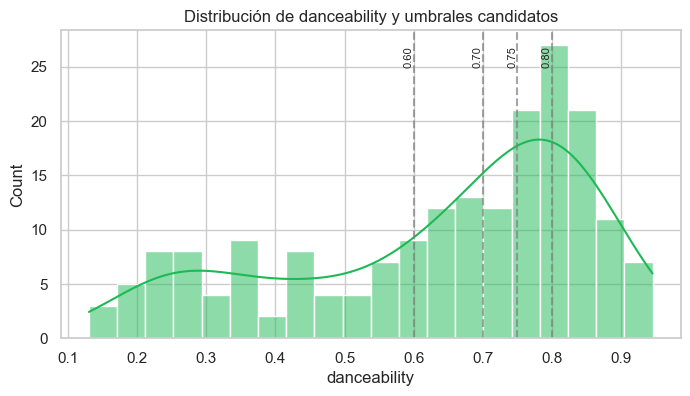

In [60]:
print(df["danceability"].describe().round(3))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["danceability"], bins=20, kde=True, color="#1DB954", ax=ax)
for u in [0.60, 0.70, 0.75, 0.80]:
    ax.axvline(u, color="gray", linestyle="--", alpha=.7)
    ax.text(u, ax.get_ylim()[1]*0.95, f"{u:.2f}", rotation=90, va="top", ha="right", fontsize=8)
ax.set_title("Distribución de danceability y umbrales candidatos")
plt.show()

In [61]:
umbrales = [0.60, 0.70, 0.75, 0.80]
tabla = pd.DataFrame({
    "umbral": umbrales,
    "bailables (1)": [(df["danceability"] >= u).sum() for u in umbrales],
    "no bailables (0)": [(df["danceability"] < u).sum() for u in umbrales],
})
tabla["% bailables"] = (tabla["bailables (1)"] / len(df) * 100).round(1)
display(tabla)

,umbral,bailables (1),no bailables (0),% bailables
0,0.60,129,66,66.2
1,0.70,101,94,51.8
2,0.75,82,113,42.1
3,0.80,49,146,25.1


> **"Perfecto. Acabamos de tomar una decisión de diseño experimental."**
> Mantendremos **0.70** como criterio inicial, dejando claro que es modificable y evaluable (sección 13).

**Pregunta para la clase:** ¿Qué pasaría con un umbral de 0.95? ¿Y de 0.10? ¿Por qué un target casi sin positivos (o casi sin negativos) es un mal punto de partida?

## 8. Crear el target `is_danceable` y comprobar el balance
**Instrucciones:** ejecuta la celda; documenta la codificación `0 = No bailable`, `1 = Bailable`.

**¿Por qué?** El **balance de clases** condiciona la métrica: si el 90% de las canciones fueran "no bailables", un modelo que siempre diga "no" tendría 90% de accuracy sin aprender nada. Por eso más adelante compararemos contra un **baseline**.

,clase,conteo,porcentaje
is_danceable,,,
0,No bailable,94,48.2
1,Bailable,101,51.8


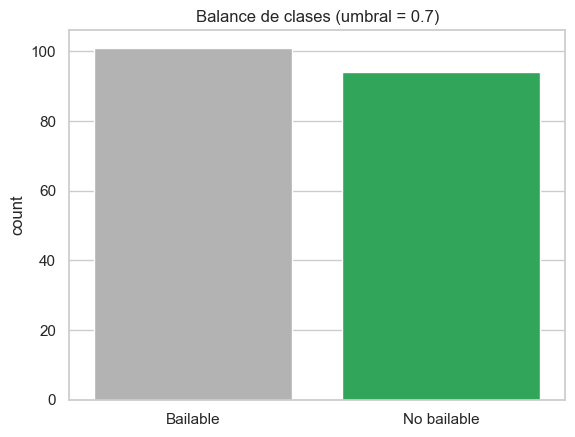

,danceability,is_danceable
144,0.130,0
12,0.297,0
49,0.462,0
14,0.640,0
112,0.705,1
184,0.762,1
20,0.798,1
123,0.847,1


In [62]:
UMBRAL = 0.70
df["is_danceable"] = (df["danceability"] >= UMBRAL).astype(int)

# Documentación del target
ETIQUETAS = {0: "No bailable", 1: "Bailable"}

balance = df["is_danceable"].value_counts().sort_index()
resumen = pd.DataFrame({"clase": [ETIQUETAS[i] for i in balance.index],
                        "conteo": balance.values,
                        "porcentaje": (balance.values / len(df) * 100).round(1)}, index=balance.index)
display(resumen)

ax = sns.countplot(x=df["is_danceable"].map(ETIQUETAS), palette=["#B3B3B3", "#1DB954"])
ax.set_title(f"Balance de clases (umbral = {UMBRAL})"); ax.set_xlabel(""); plt.show()

display(df[["danceability", "is_danceable"]].sort_values("danceability").iloc[::max(1, len(df)//8)].head(8))

**Pregunta para la clase:** ¿Está balanceado el target? Si no lo está, ¿qué métrica nos conviene mirar además del accuracy? 

## 9. Demostración de *data leakage*
**Instrucciones:** ejecuta la celda: entrenamos dos veces el mismo modelo, una **incluyendo** `danceability` como feature y otra **sin** ella.

**¿Por qué?** `is_danceable` se **calculó** a partir de `danceability`. Dárselo al modelo es darle la respuesta del examen: obtendrá un resultado casi perfecto que **no sirve de nada** porque en la vida real no conoceríamos `danceability` si lo que queremos es predecirla. Mostrarlo en vivo se recuerda mucho mejor que contarlo.

In [63]:
audio_base = ["energy","loudness","valence","acousticness","instrumentalness","speechiness","liveness","mode","key"]
audio_base = [c for c in audio_base if c in df.columns]

def evaluar(features, nombre):
    X_ = df[features]; y_ = df["is_danceable"]
    Xtr, Xte, ytr, yte = train_test_split(X_, y_, test_size=0.25, stratify=y_, random_state=RANDOM_STATE)
    m = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xtr, ytr)
    return {"escenario": nombre, "n_features": len(features),
            "accuracy test": round(accuracy_score(yte, m.predict(Xte)), 3)}

res_leak = pd.DataFrame([
    evaluar(audio_base + ["danceability"], "CON danceability (leakage)"),
    evaluar(audio_base,                     "SIN danceability (correcto)"),
])
display(res_leak)

,escenario,n_features,accuracy test
0,CON danceability (leakage),10,1.000
1,SIN danceability (correcto),9,0.633


**Pregunta para la clase:**¿Por qué el primer modelo "parece" mejor? ¿Qué otras columnas podrían ser leakage en otros problemas? *(ej.: predecir una enfermedad usando "toma el medicamento X")*

**Nota docente:** aprovecha para introducir `liked`. No es leakage matemático de `is_danceable`, pero **no es una característica de la canción**, sino la opinión de una persona; no pertenece a este primer experimento.

## 10. Selección justificada de features
**Instrucciones:** ejecuta la celda y revisa la tabla: **cada columna entra o sale con una razón escrita**.

**¿Por qué?** Tener datos **no significa** que todos deban entrar al modelo. Empezamos deliberadamente con **pocas variables** para entender el efecto de cada decisión; después podremos añadir y medir.

In [64]:
FEATURES = ["energy","loudness","valence","acousticness","instrumentalness",
            "speechiness","liveness","mode","key"]

DECISIONES = {
    "danceability": ("Fuera", "Se usó para crear el target → leakage"),
    "is_danceable": ("Target", "Variable que queremos predecir"),
    "liked":        ("Fuera", "Opinión de una persona, no característica de la canción (posible Experimento 3)"),
    "tempo":        ("Fuera por ahora", "Candidata clara para el Experimento 2 (¿mejora al añadirla?)"),
    "duration_ms":  ("Fuera por ahora", "Fuera del foco musical del primer modelo"),
    "time_signature": ("Fuera por ahora", "Casi constante en la mayoría de canciones"),
    "popularity":   ("Fuera (si existe)", "Experimento 2: ¿la popularidad mejora la predicción?"),
    "explicit":     ("Fuera por ahora", "Posible feature futura"),
    "track_id":     ("Fuera (si existe)", "Identificador: no aporta información musical"),
    "name":         ("Fuera (si existe)", "Texto; a futuro, NLP sobre título/letra"),
    "artists":      ("Fuera (si existe)", "Alta cardinalidad"),
    "album":        ("Fuera (si existe)", "Alta cardinalidad"),
    "genre":        ("Análisis (si existe)", "Posible target de otro experimento"),
}
for f in FEATURES:
    DECISIONES[f] = ("Feature", "Característica musical del primer modelo")

faltan = [f for f in FEATURES if f not in df.columns]
assert not faltan, f"Faltan features requeridas: {faltan}"

tab = pd.DataFrame([(c, *DECISIONES.get(c, ("Sin decidir", "Columna no contemplada en el plan")))
                    for c in df.columns], columns=["columna", "decisión", "justificación"])
display(tab.sort_values("decisión").reset_index(drop=True))

,columna,decisión,justificación
0,energy,Feature,Característica musical del primer modelo
1,key,Feature,Característica musical del primer modelo
2,loudness,Feature,Característica musical del primer modelo
3,mode,Feature,Característica musical del primer modelo
4,speechiness,Feature,Característica musical del primer modelo
5,acousticness,Feature,Característica musical del primer modelo
6,instrumentalness,Feature,Característica musical del primer modelo
7,liveness,Feature,Característica musical del primer modelo
8,valence,Feature,Característica musical del primer modelo
9,danceability,Fuera,Se usó para crear el target → leakage


**Detalle fino que conviene discutir:** `key` es **categórica nominal** codificada como número. En este primer modelo la dejamos tal cual (como en el plan) para mantener la simplicidad, pero es un buen **ejercicio propuesto** transformarla con *one-hot encoding* y comparar resultados.

**Pregunta para la clase:** ¿Qué columna dejarían fuera que nosotros dejamos dentro, o al revés? Argumenten con datos, no con intuición.

## 11. Construcción de `X` / `y` y partición Train / Test
**Instrucciones:** ejecuta la celda y verifica que el porcentaje de la clase positiva sea **similar** en train y test.

**¿Por qué?** Separamos datos para evaluar con canciones que el modelo **nunca vio** (simula el mundo real). Usamos `stratify=y` para mantener la proporción de clases, algo crítico con **pocos datos**: sin estratificar, un test con muy pocos positivos daría métricas inestables.

In [65]:
X = df[FEATURES]
y = df["is_danceable"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

print(f"X: {X.shape} | y: {y.shape}")
print(f"Train: {len(X_train)} filas | Test: {len(X_test)} filas")
print("\n% bailables  ->  total: {:.1f} | train: {:.1f} | test: {:.1f}".format(
    y.mean()*100, y_train.mean()*100, y_test.mean()*100))

X: (195, 9) | y: (195,)
Train: 146 filas | Test: 49 filas

% bailables  ->  total: 51.8 | train: 52.1 | test: 51.0


## 12. Primer experimento: baseline vs. modelos simples *(extensión)*
**Instrucciones:** ejecuta las celdas: comparamos un **baseline** (siempre predice la clase mayoritaria), una **regresión logística** (con escalado) y un **árbol de decisión limitado**.

**¿Por qué?** Un modelo solo es "bueno" si **supera al baseline**. La regresión logística necesita **escalar** las variables (`loudness` y `energy` viven en escalas muy distintas); el árbol no. Con ~200 filas, además del test usamos **validación cruzada** para saber cuánta confianza darle a un único número.

In [66]:
modelos = {
    "Baseline (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
    "Regresión logística":          make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Árbol (max_depth=3)":          DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

filas = []
for nombre, m in modelos.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    cv_acc = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    filas.append({"modelo": nombre,
                  "accuracy test": round(accuracy_score(y_test, pred), 3),
                  "F1 test": round(f1_score(y_test, pred, zero_division=0), 3),
                  "accuracy CV (media ± std)": f"{cv_acc.mean():.3f} ± {cv_acc.std():.3f}"})
display(pd.DataFrame(filas))

,modelo,accuracy test,F1 test,accuracy CV (media ± std)
0,Baseline (clase mayoritaria),0.510,0.676,0.518 ± 0.010
1,Regresión logística,0.694,0.681,0.774 ± 0.041
2,Árbol (max_depth=3),0.673,0.714,0.697 ± 0.107


              precision    recall  f1-score   support

 No bailable       0.67      0.75      0.71        24
    Bailable       0.73      0.64      0.68        25

    accuracy                           0.69        49
   macro avg       0.70      0.70      0.69        49
weighted avg       0.70      0.69      0.69        49



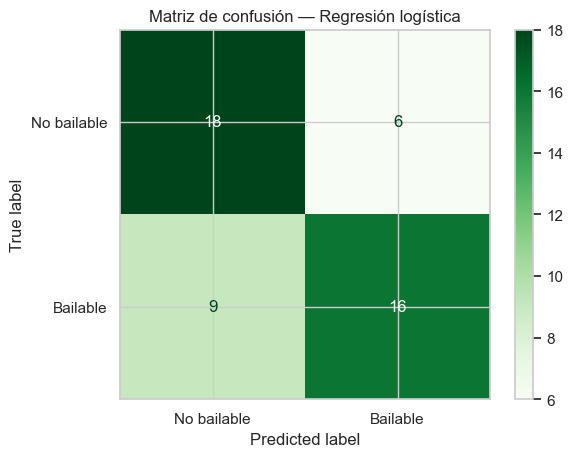

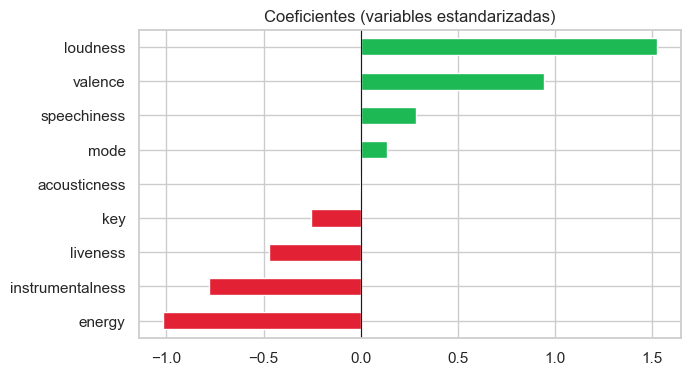

In [67]:
mejor = modelos["Regresión logística"]
print(classification_report(y_test, mejor.predict(X_test), target_names=[ETIQUETAS[0], ETIQUETAS[1]], zero_division=0))
ConfusionMatrixDisplay.from_estimator(mejor, X_test, y_test, display_labels=[ETIQUETAS[0], ETIQUETAS[1]], cmap="Greens")
plt.title("Matriz de confusión — Regresión logística"); plt.show()

coef = pd.Series(mejor.named_steps["logisticregression"].coef_[0], index=FEATURES).sort_values()
coef.plot(kind="barh", color=["#E22134" if v < 0 else "#1DB954" for v in coef], figsize=(7, 4))
plt.title("Coeficientes (variables estandarizadas)"); plt.axvline(0, color="k", lw=.8); plt.show()

**Preguntas para la clase:**
- ¿Supera algún modelo al baseline? ¿Por cuánto? ¿Es esa diferencia "grande" dado el tamaño del dataset?
- Según los coeficientes, ¿qué características se asocian con una canción bailable? ¿Tiene sentido musical?
- **Correlación no es causalidad:** que `valence` alta se asocie a "bailable" no significa que alegrar una canción la haga bailable.

**Nota docente:** con ~195 canciones de **una sola persona** (mucho rap francés en las *liked*), los resultados **no generalizan a toda la música**. Es un buen momento para hablar de **sesgo de muestreo** y de la importancia del tamaño y representatividad de los datos.

## 13. Sensibilidad del umbral: ¿la decisión de diseño importa?
**Instrucciones:** ejecuta la celda: repetimos el experimento con distintos umbrales.

**¿Por qué?** Convierte la "decisión de diseño" en algo **medible**. Atención: las métricas **no son directamente comparables** entre umbrales porque el problema cambia (distinto balance de clases); por eso se muestra también el *baseline* de cada caso.

In [68]:
filas = []
for u in [0.60, 0.70, 0.75, 0.80]:
    yy = (df["danceability"] >= u).astype(int)
    if yy.nunique() < 2 or yy.value_counts().min() < 10:
        filas.append({"umbral": u, "nota": "muy pocas muestras de una clase"}); continue
    Xtr, Xte, ytr, yte = train_test_split(df[FEATURES], yy, test_size=0.25, stratify=yy, random_state=RANDOM_STATE)
    base = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    filas.append({"umbral": u, "% positivos": round(yy.mean()*100, 1),
                  "accuracy baseline": round(accuracy_score(yte, base.predict(Xte)), 3),
                  "accuracy modelo": round(accuracy_score(yte, lr.predict(Xte)), 3),
                  "F1 modelo": round(f1_score(yte, lr.predict(Xte), zero_division=0), 3)})
display(pd.DataFrame(filas).fillna("-"))

,umbral,% positivos,accuracy baseline,accuracy modelo,F1 modelo
0,0.60,66.2,0.653,0.857,0.896
1,0.70,51.8,0.510,0.694,0.681
2,0.75,42.1,0.571,0.694,0.651
3,0.80,25.1,0.755,0.796,0.545


### Próximos experimentos (tareas para los estudiantes)
| # | Experimento | Pregunta | Qué se aprende |
|---|---|---|---|
| 2 | Añadir `tempo`, `duration_ms` (y `popularity` si existe) | ¿Mejora la predicción? | Efecto de añadir features |
| 3 | Target `liked` en lugar de `is_danceable` | ¿Podemos predecir el gusto de **una** persona? | Sistemas de recomendación, sesgo personal |
| 4 | *One-hot* para `key` | ¿Tratar `key` como categórica ayuda? | Codificación de variables |
| 5 | Predecir `genre` | ¿El audio revela el género? | Clasificación multiclase *(solo si el CSV trae `genre`)* |

## 14. Exportar el dataset construido
**Instrucciones:** ejecuta la celda: guarda el dataset completo con `is_danceable` y las particiones train/test.

**¿Por qué?** Guardar las particiones asegura que **todos los estudiantes trabajen con exactamente los mismos datos** y permite retomar el trabajo sin repetir el pipeline. Es también el primer paso hacia un flujo reproducible.

In [69]:
os.makedirs("salida", exist_ok=True)
df.to_csv("salida/spotify_ia_aplicada.csv", index=False)

train = X_train.assign(is_danceable=y_train)
test  = X_test.assign(is_danceable=y_test)
train.to_csv("salida/train.csv", index=False)
test.to_csv("salida/test.csv", index=False)

print("Archivos generados en ./salida :")
for f in sorted(os.listdir("salida")): print("  -", f)

Archivos generados en ./salida :
  - spotify_ia_aplicada.csv
  - test.csv
  - train.csv


## 15. Cierre de la clase
### Resumen del experimento
| Elemento | Valor |
|---|---|
| Target | `is_danceable` = (`danceability` ≥ 0.70) |
| Features iniciales | energy, loudness, valence, acousticness, instrumentalness, speechiness, liveness, mode, key |
| Fuera del primer modelo | danceability (leakage), liked, tempo, duration_ms, time_signature, y columnas de texto/ID si existen |

### Ideas clave para llevarse
1. **Auditar antes de modelar:** el dataset real rara vez coincide con el plan.
2. **El target es una decisión de diseño**, no un dato natural.
3. **Leakage:** un resultado demasiado bueno es motivo de sospecha, no de celebración.
4. **Baseline primero:** un modelo vale lo que mejora sobre uno trivial.
5. **Con pocos datos, mucha cautela:** estratificar, validar de forma cruzada y no sobre-interpretar.
